In [1]:
import numpy as np
from cosmoTransitions.tunneling1D import SingleFieldInstanton
import matplotlib.pyplot as plt
import pandas as pd
from scipy import optimize as optimize
import scipy.integrate as integrate
from scipy import interpolate, special


####Some definitions##
v2 = 246.**2 
mh=125
v=246
alpha=1/137 #fine structure constant
sinthw=np.sqrt(0.223) #sine of Weinberg angle
g1=np.sqrt(4*np.pi*alpha/(1-sinthw**2)) ## U(1)_Y gauge coupling constant
g=np.sqrt(4*np.pi*alpha)/sinthw #SU(2)_L gauge coupling constant
Mplanck=2.4*10**18 #reduced planck mass
mZ=np.sqrt(v**2/4*(g**2+g1**2))###Z boson mass

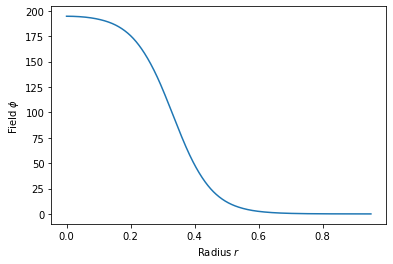

In [31]:
#Definition of the potential#
Tc = 100.
L = 0.1*Tc**4
sigma = 0.1*Tc**3
lc = 6/Tc
T0 = Tc/(1+6*sigma/(L*lc))**0.5
a = 1/(2/3*sigma*lc**5*Tc**2)**0.5
gamma = (L+6*sigma/lc)/(6*sigma*lc*Tc**2)
lam = 1/(3*sigma*lc**3)
T = 93.
def V(phi): return 0.5*gamma*(T**2-T0**2)*phi**2-1/3*a*T*phi**3+0.25*lam*phi**4
def dV(phi): return gamma*(T**2-T0**2)*phi-a*T*phi**2+lam*phi**3

#critical bubble#
xi = np.array(range(25000))*0.01
Vmin = np.amin(V(xi))
vt = xi[np.where(V(xi) == Vmin)[0]][0] ##find location of the global minimum
profile = SingleFieldInstanton(vt, 0.0, V, dV).findProfile(npoints=1000)
plt.plot(profile.R, profile.Phi)
plt.xlabel(r"Radius $r$")
plt.ylabel(r"Field $\phi$")
plt.show()

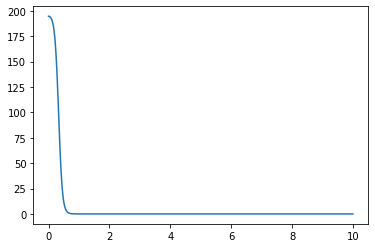

In [32]:
#initialization of the evolution#
fphi = interpolate.interp1d(profile.R, profile.Phi, fill_value=(0), bounds_error=False)
dr=0.01
r  = np.array(range(0,len(profile.R)))*dr
phi0 = fphi(r)
phi2 = np.zeros(profile.Phi.size)
plt.plot(r,phi0)
plt.show()

/opt/anaconda3/envs/cosmoT/lib/python3.6/site-packages/ipykernel_launcher.py:12: RuntimeWarning: overflow encountered in double_scalars
  if sys.path[0] == '':
/opt/anaconda3/envs/cosmoT/lib/python3.6/site-packages/ipykernel_launcher.py:12: RuntimeWarning: invalid value encountered in double_scalars
  if sys.path[0] == '':
/opt/anaconda3/envs/cosmoT/lib/python3.6/site-packages/ipykernel_launcher.py:11: RuntimeWarning: invalid value encountered in double_scalars
  # This is added back by InteractiveShellApp.init_path()
/opt/anaconda3/envs/cosmoT/lib/python3.6/site-packages/ipykernel_launcher.py:13: RuntimeWarning: invalid value encountered in double_scalars
  del sys.path[0]


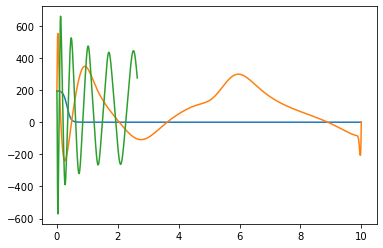

In [4]:
####Solving equation (8) of arxiv:9512202 with \eta=0
###Lattice approach:

dt = 0.002
phi_lattice=[]
phi2_lattice=[]
phi=phi0
for i in range(10000):#---------------------------------------------iterate over time
    phi = 0.5*dt*phi2 + phi
    for j in range(1,len(phi2)-1):  #------------------------------iterate over space
        dphi_dr=(phi[j+1]-phi[j-1])/(2*dr) # ------------------first spatial derivative 
        d2phi_dr2 = (phi[j+1]+phi[j-1]-2*phi[j])/(dr**2) #---------second spatial derivative 
        phi2[j]=phi2[j-1] +  dt*(d2phi_dr2 + 2*dphi_dr/r[j]-dV(phi[j]))
    phi = 0.5*dt*phi2 +phi
    phi_lattice.append(list(phi))
    phi2_lattice.append(list(phi2))
    if(i%1000==0):
        plt.plot(r,phi)

phi_lattice_array=np.array(phi_lattice)
phi2_lattice_array=np.array(phi2_lattice)    

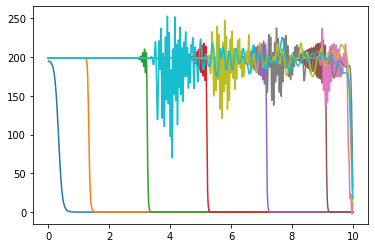

In [33]:
####Solving equation (8) of arxiv:9512202 with \eta=0
###Lattice approach:

dt = 0.002
phi=phi0
for i in range(10000):#--------------------------------------------------iterate over time
    #------1 step evolution
    phi = 0.5*dt*phi2 + phi
    lphi=np.append(phi[1:],0)
    rphi=np.append(phi[0],phi[:-1])
    #------2nd step evolution 
    dphi_dr=(lphi-rphi)/(2*dr) #----------------------------------first spatial derivative
    d2phi_dr2 = (lphi + rphi - 2 * phi)/(dr**2) #----------------------2nd spatial derivative
    phi2 = phi2 + dt*(d2phi_dr2 + 2/(r+dr)*dphi_dr - dV(phi) )
    #-------3rd step evolution
    phi = 0.5*dt*phi2 +phi
    if(i%1000==0):
        plt.plot(r,phi)

   